In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/uciml/mushroom-classification/mushrooms.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/uciml/mushroom-classification/mushrooms.csv')

display(df.head(3))

# descobrimos o que contem nas colunas; vemos que ? sao valores nulos e estao apenas em stalk root
#for coluna in df.columns:
#    print(f"\n{coluna}:")
#    print(df[coluna].unique())

# printa caracteristicas do stalk root
print(df["stalk-root"].value_counts(dropna=False))

print(f'\nDimensões: {df.shape}')
print(f'Valores "?": {(df == "?").sum().sum()}')
print(f'Duplicados: {df.duplicated().sum()}', '\n')

# classes e qntd de caracteristicas
df.info()

print('\nDistribuição das classes:')
print(df['class'].value_counts())

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m


stalk-root
b    3776
?    2480
e    1120
c     556
r     192
Name: count, dtype: int64

Dimensões: (8124, 23)
Valores "?": 2480
Duplicados: 0 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   

In [3]:
from sklearn.preprocessing import LabelEncoder

df = df.replace('?', 'unknown')
print(df['stalk-root'].value_counts())

X = df.drop(['class'],axis=1) # exclui coluna classe
y = df['class'] # cria coluna classe para o y

encoder = LabelEncoder()
y = encoder.fit_transform(y)
print(y)
# e = 0, p = 1
# [p e e ... e p e]

# nao teremos validacao
# stratify faz uma distribuicao proporcional de venenosos e comestiveis
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("\nTreino:", X_train.shape)
print("Teste:", X_test.shape)

X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)# substitui o false por 0 e true por 1
X_train.head(3)

stalk-root
b          3776
unknown    2480
e          1120
c           556
r           192
Name: count, dtype: int64
[1 0 0 ... 0 1 0]

Treino: (6499, 22)
Teste: (1625, 22)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
5249,0,0,1,0,0,0,0,0,0,1,...,0,0,1,0,1,0,0,0,0,0
5781,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
7586,1,0,0,0,0,0,0,0,1,0,...,1,0,0,0,1,0,0,0,0,0


In [4]:
def imprimir_resultados(nome_modelo, y_test, y_pred):
    print(f"\n== Metricas - {nome_modelo} ==")
    print(f"Acuracia: {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precisao: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall: {recall_score(y_test, y_pred):.4f}")
    print(f"F1-score: {f1_score(y_test, y_pred):.4f}")

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    print(f"- Comestíveis classificados corretamente (Verdadeiros Negativos): {tn}")
    print(f"- Venenosos classificados corretamente (Verdadeiros Positivos): {tp}")
    print(f"- ERRO: Comestíveis classificados como venenosos (Falsos Positivos): {fp}")
    print(f"- ERRO: Venenosos classificados como comestíveis (Falsos Negativos): {fn}\n")


== Decision Tree ==
Profundidade: 1
Treino: 0.8871 | Teste: 0.8855
Profundidade: 2
Treino: 0.9555 | Teste: 0.9489
Profundidade: 3
Treino: 0.9860 | Teste: 0.9822
Profundidade: 5
Treino: 0.9998 | Teste: 0.9988
Profundidade: 10
Treino: 1.0000 | Teste: 1.0000
Profundidade: None
Treino: 1.0000 | Teste: 1.0000

== Random Forest ==
Arvores: 2 | Profundidade: 1 | Treino: 0.8491 | Teste: 0.8308
Arvores: 2 | Profundidade: 2 | Treino: 0.9511 | Teste: 0.9520
Arvores: 2 | Profundidade: 3 | Treino: 0.9671 | Teste: 0.9692
Arvores: 2 | Profundidade: 5 | Treino: 0.9905 | Teste: 0.9889
Arvores: 2 | Profundidade: 10 | Treino: 0.9995 | Teste: 0.9982
Arvores: 2 | Profundidade: None | Treino: 1.0000 | Teste: 1.0000
Arvores: 3 | Profundidade: 1 | Treino: 0.8491 | Teste: 0.8308
Arvores: 3 | Profundidade: 2 | Treino: 0.8783 | Teste: 0.8689
Arvores: 3 | Profundidade: 3 | Treino: 0.9378 | Teste: 0.9458
Arvores: 3 | Profundidade: 5 | Treino: 0.9754 | Teste: 0.9705
Arvores: 3 | Profundidade: 10 | Treino: 0.9995 |

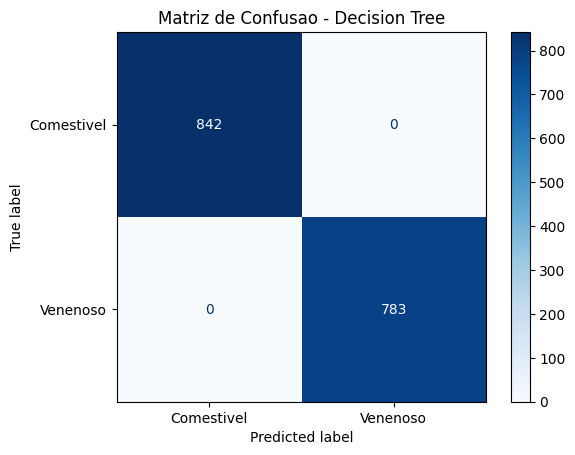

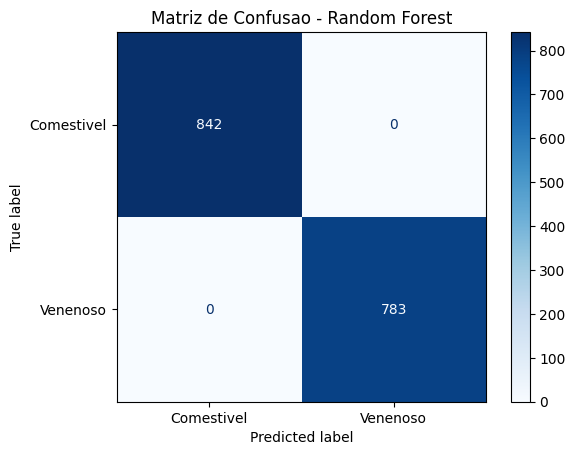

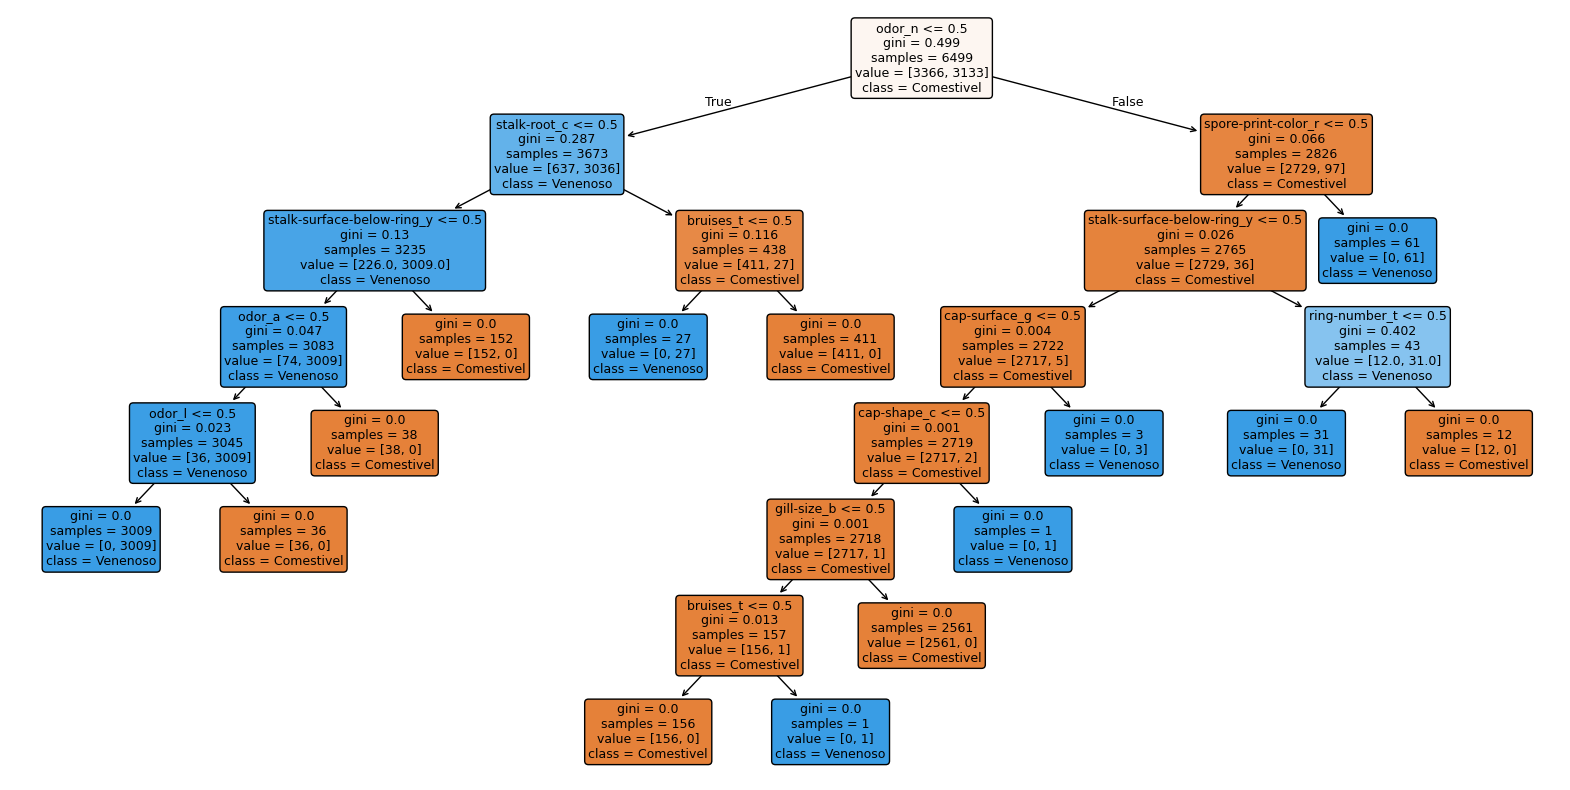

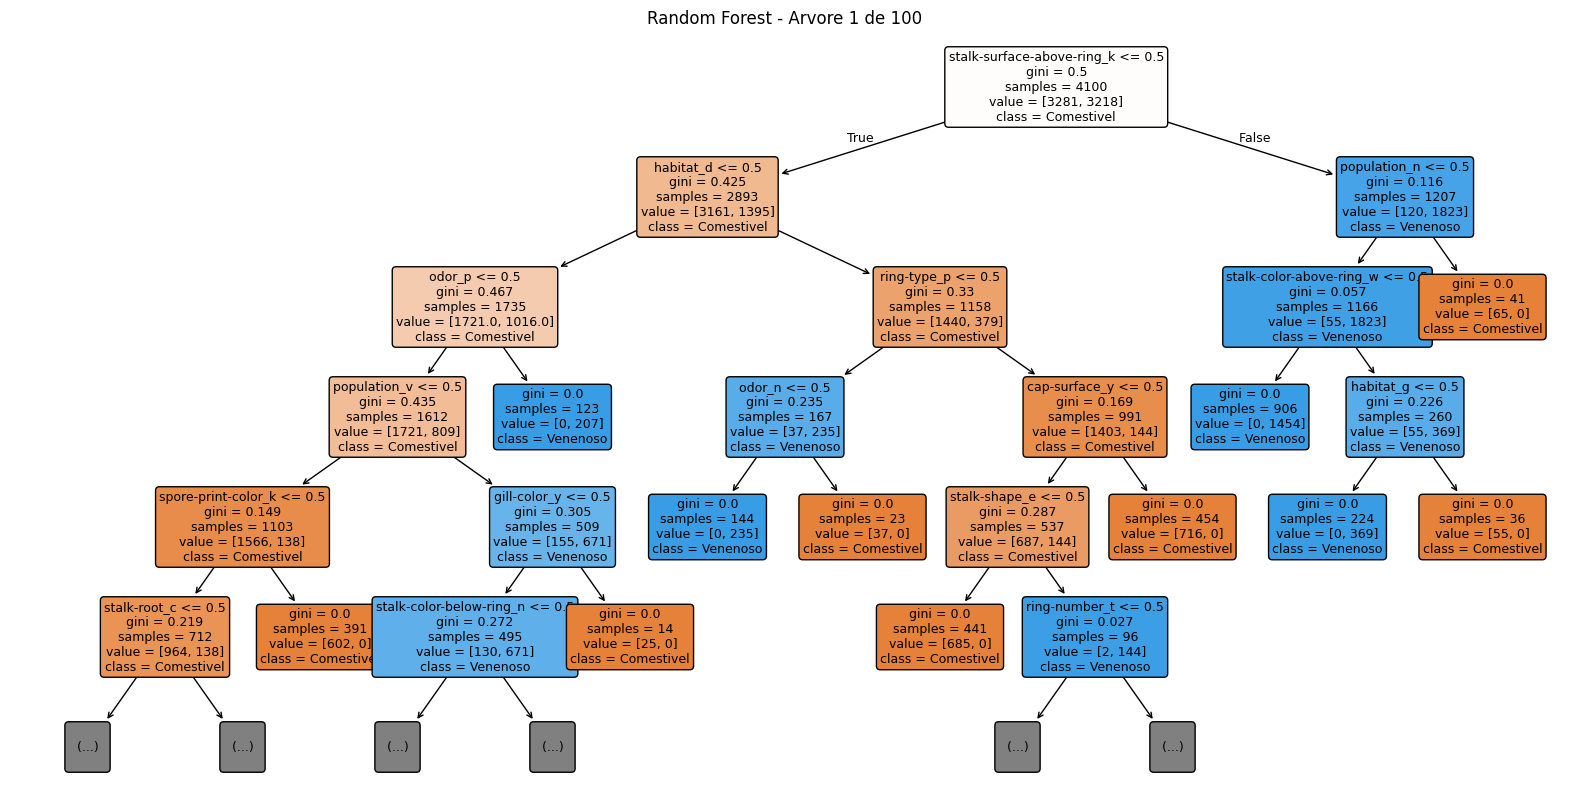

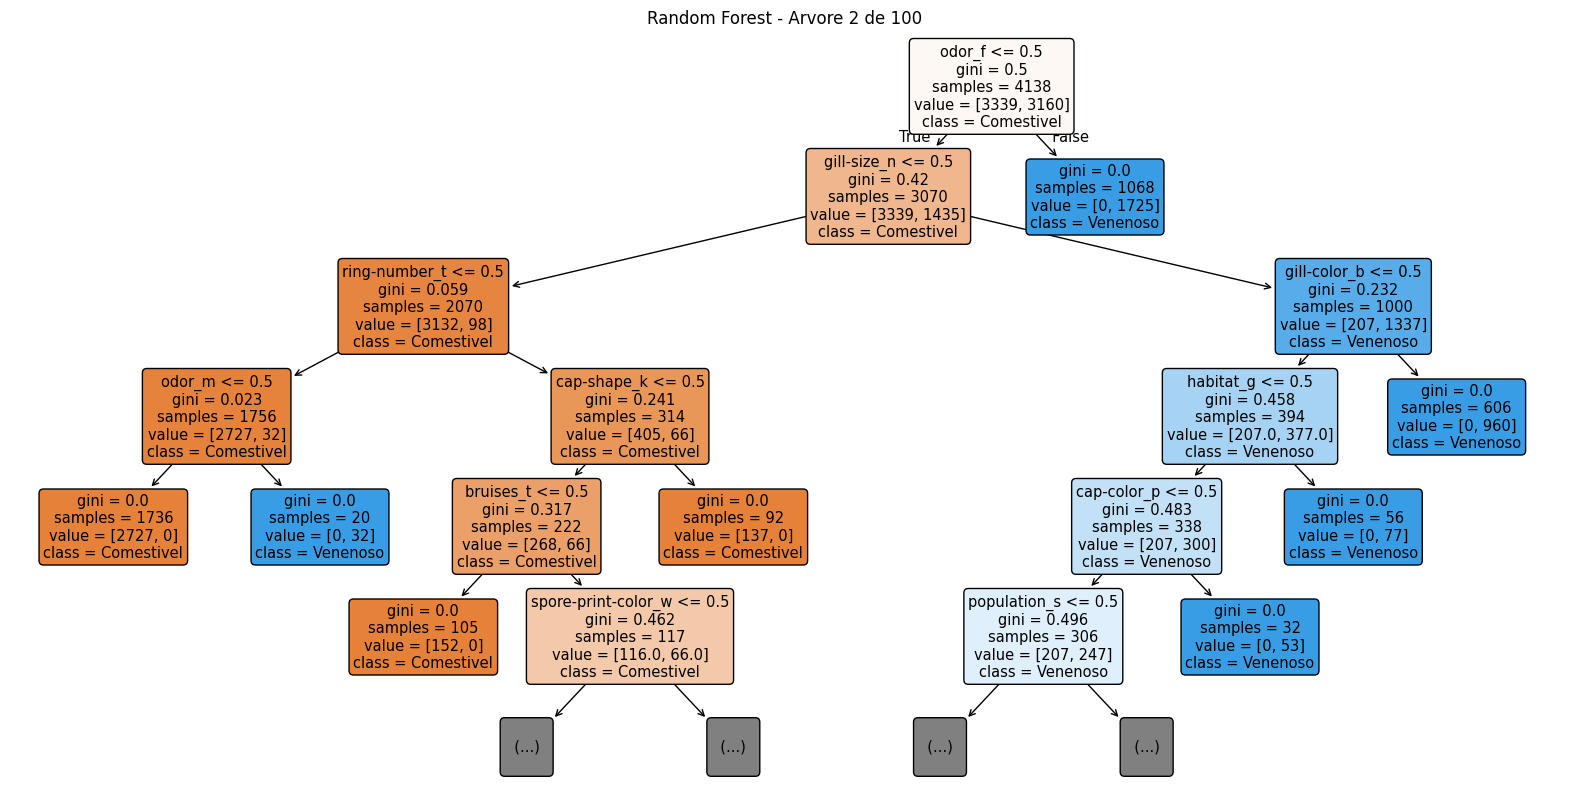

In [5]:
# Modelos
print("\n== Decision Tree ==")
for profundidade in [1, 2, 3, 5, 10, None]:
    modelo_dt = DecisionTreeClassifier(max_depth=profundidade, random_state=42)
    modelo_dt.fit(X_train, y_train)
    y_pred = modelo_dt.predict(X_test)

    print(f"Profundidade: {profundidade}")
    print(f"Treino: {modelo_dt.score(X_train, y_train):.4f} | Teste: {accuracy_score(y_test, y_pred):.4f}")

print("\n== Random Forest ==")
for n in [2, 3, 4]:
    for profundidade in [1, 2, 3, 5, 10, None]:
        modelo_rf = RandomForestClassifier(n_estimators=n, max_depth=profundidade, random_state=42)
        modelo_rf.fit(X_train, y_train)
        y_pred = modelo_rf.predict(X_test)

        print(f"Arvores: {n} | Profundidade: {profundidade} | Treino: {modelo_rf.score(X_train, y_train):.4f} | Teste: {accuracy_score(y_test, y_pred):.4f}")

modelo_dt = DecisionTreeClassifier(random_state=42)
modelo_dt.fit(X_train, y_train)
y_pred_dt = modelo_dt.predict(X_test)

modelo_rf = RandomForestClassifier(random_state=42)
modelo_rf.fit(X_train, y_train)
y_pred_rf = modelo_rf.predict(X_test)

# metricas finais, calculados pela ilimitacao de profundidade, 100 arvores no caso do random forest
imprimir_resultados("Decision Tree", y_test, y_pred_dt)
imprimir_resultados("Random Forest", y_test, y_pred_rf)

# matrizes de confusao
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt, display_labels=["Comestivel", "Venenoso"], cmap="Blues")
plt.title("Matriz de Confusao - Decision Tree")
plt.savefig("matriz_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=["Comestivel", "Venenoso"], cmap="Blues")
plt.title("Matriz de Confusao - Random Forest")
plt.savefig("matriz_random_forest.png", dpi=300, bbox_inches="tight")
plt.show()


# plota arvore decision tree
plt.figure(figsize=(20, 10))
plot_tree(modelo_dt, feature_names=X_train.columns, class_names=["Comestivel", "Venenoso"], filled=True, rounded=True, fontsize=9)
plt.savefig("arvore_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()


# plota a primeira arvore do Random Forest final (100 arvores)
plt.figure(figsize=(20, 10))
plot_tree(modelo_rf.estimators_[0], feature_names=X_train.columns, class_names=["Comestivel", "Venenoso"], filled=True, rounded=True, max_depth=5, fontsize=9)
plt.title("Random Forest - Arvore 1 de 100")
plt.savefig("arvore_random_forest.png", dpi=300, bbox_inches="tight")
plt.show()

# plota a segunda arvore do Random Forest final (100 arvores)
plt.figure(figsize=(20, 10))
plot_tree(modelo_rf.estimators_[1], feature_names=X_train.columns, class_names=["Comestivel", "Venenoso"], filled=True, rounded=True, max_depth=5)
plt.title("Random Forest - Arvore 2 de 100")
plt.savefig("arvore_random_forest2.png", dpi=300, bbox_inches="tight")
plt.show()


Atributos mais importantes - Decision Tree
odor_n                        0.617790
stalk-root_c                  0.179322
stalk-surface-below-ring_y    0.098528
spore-print-color_r           0.035830
odor_a                        0.022586
odor_l                        0.021923
bruises_t                     0.016226
ring-number_t                 0.005331
cap-surface_g                 0.001844
cap-shape_c                   0.000616
gill-size_b                   0.000004
cap-shape_s                   0.000000
cap-shape_x                   0.000000
cap-color_g                   0.000000
cap-color_n                   0.000000


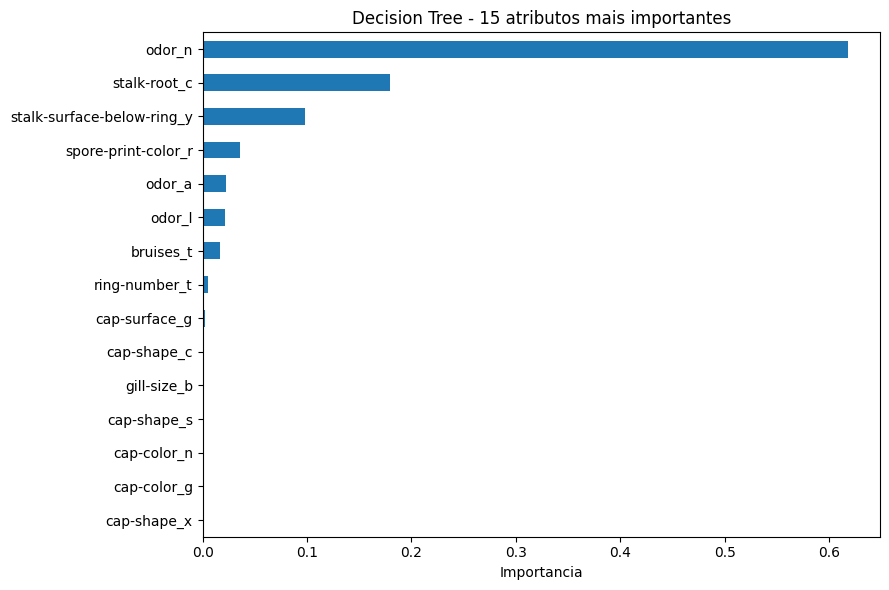


Atributos mais importantes - Random Forest (100 arvores)
odor_n                        0.141297
gill-size_n                   0.066629
odor_f                        0.057991
gill-size_b                   0.052806
spore-print-color_h           0.052684
stalk-surface-below-ring_k    0.051191
stalk-surface-above-ring_k    0.037259
ring-type_p                   0.036346
gill-color_b                  0.035292
bruises_t                     0.026549
bruises_f                     0.024500
ring-type_l                   0.020607
stalk-surface-above-ring_s    0.020459
gill-spacing_c                0.019563
population_v                  0.018518


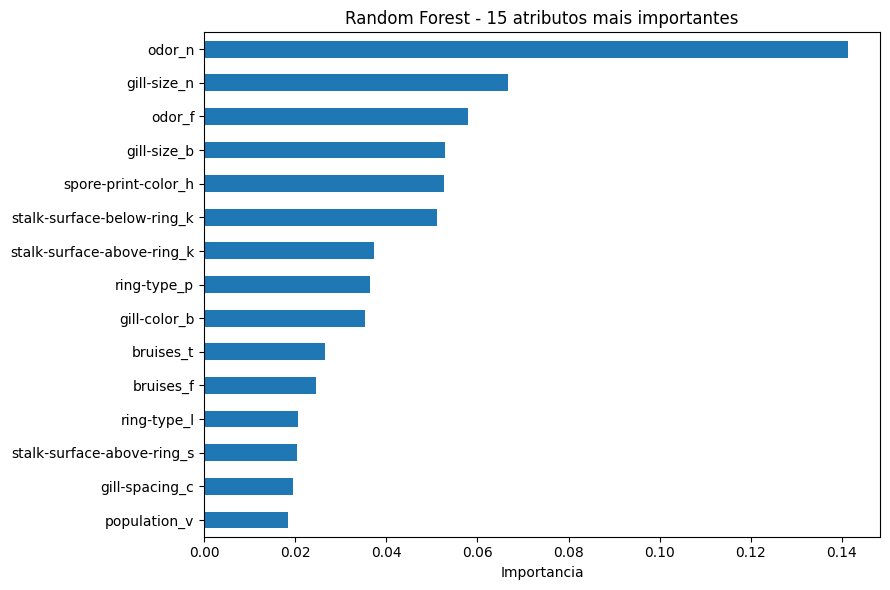

Importancia por atributo original - Random Forest
odor                        0.246231
gill-size                   0.119436
spore-print-color           0.089363
stalk-surface-below-ring    0.076440
ring-type                   0.066243
stalk-surface-above-ring    0.061386
bruises                     0.051048
gill-color                  0.045125
stalk-root                  0.042027
gill-spacing                0.037699
population                  0.036176
habitat                     0.032528
stalk-shape                 0.025992
cap-color                   0.014723
stalk-color-above-ring      0.014526
stalk-color-below-ring      0.013549
cap-surface                 0.010350
ring-number                 0.010119
cap-shape                   0.005749
veil-color                  0.000716
gill-attachment             0.000573
veil-type                   0.000000


In [6]:
# treinando de novo pra garantir que os proximos graficos vao ser esses
modelo_dt = DecisionTreeClassifier(random_state=42)
modelo_dt.fit(X_train, y_train)
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

# Importancia dos atributos - Decision Tree
importancias_dt = pd.Series(
    modelo_dt.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Atributos mais importantes - Decision Tree")
print(importancias_dt.head(15).to_string())

importancias_dt.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
plt.xlabel("Importancia")
plt.title("Decision Tree - 15 atributos mais importantes")
plt.tight_layout()
plt.savefig("/kaggle/working/importancia_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()

importancias_dt.head(15).to_csv(
    "/kaggle/working/importancia_decision_tree.csv",
    header=["Importancia"]
)

# Importancia dos atributos - Random Forest (100 arvores)
importancias_rf = pd.Series(
    modelo_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("\nAtributos mais importantes - Random Forest (100 arvores)")
print(importancias_rf.head(15).to_string())

importancias_rf.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
plt.xlabel("Importancia")
plt.title("Random Forest - 15 atributos mais importantes")
plt.tight_layout()
plt.savefig("/kaggle/working/importancia_random_forest.png", dpi=300, bbox_inches="tight")
plt.show()

importancias_rf.head(15).to_csv(
    "/kaggle/working/importancia_random_forest.csv",
    header=["Importancia"]
)


importancias_rf_originais = importancias_rf.groupby(
    lambda coluna: coluna.rsplit("_", 1)[0]
).sum().sort_values(ascending=False)

print("Importancia por atributo original - Random Forest")
print(importancias_rf_originais.to_string())